# Expected vs. Delivered: Measuring Response Fulfillment in Everyday Conversations

## Mistral-7B — Joint Supervised Fine-tuning (3 Tasks, 5 Folds)

This project investigates the relationship between the response expected by a previous utterance, the actual function of the delivered response, and whether that response fulfills the expectation. This notebook trains one shared Mistral-7B LoRA adapter per fold on instruction examples for all three tasks.

| Task | Input columns | Target label |
|---|---|---|
| Expected | `previous_utterance` | `Expected Response Function` |
| Actual | `previous_utterance`, `response` | `Actual Function` |
| Fulfillment | `context`, `previous_utterance`, `response` | `Fulfillment` |

**Dataset:** `final_annotated_dataset.csv` (2,215 labeled pairs in the supplied final version). The source file is read directly and never modified. Five grouped folds are generated in memory using a fixed deterministic procedure; all tasks share the same split. Dialogue IDs and identical normalized previous utterances cannot cross the train/test boundary.

**Sources:** Task inputs from `03_Classification (2)(1).ipynb`; taxonomy definitions from `Dialogue_Annotation(1).ipynb`. Mismatch Type is not a classification target.

**Evaluation:** Accuracy, macro/weighted precision, recall and F1, per-class reports, count and row/column-normalized confusion matrices, and mean ± sample standard deviation across completed folds. Run on a Colab GPU. Change `FOLD` from 1 through 5, training a fresh adapter for each fold. Results are written to a dataset-specific Drive directory.

## 1. Install required packages

In [ ]:
# Run once in a fresh Colab session. Restart the session after installation.
%pip -q install -U unsloth trl transformers datasets accelerate peft bitsandbytes scikit-learn "pandas==2.2.3"
# We do not use experiment tracking; remove the conflicting optional library.
%pip uninstall -y wandb

Found existing installation: wandb 0.28.1
Uninstalling wandb-0.28.1:
  Successfully uninstalled wandb-0.28.1


## 2. Settings, Google Drive, and imports

In [ ]:
# Import Unsloth before torch/transformers.
import unsloth
from unsloth import FastLanguageModel
import os, json, random, gc, re, hashlib
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from trl import SFTTrainer, SFTConfig
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import drive, files
from tqdm.auto import tqdm

drive.mount('/content/drive')
assert torch.cuda.is_available(), 'Set Runtime → Change runtime type → GPU first.'
print('GPU:',torch.cuda.get_device_name(0))

SEED = 42
FOLD = 1                    # 1, 2, 3, 4, or 5 (ONE shared model for ALL 3 tasks per fold)
NUM_TRAIN_EPOCHS = 1
MAX_SEQ_LENGTH = 1024
MODEL_NAME = 'unsloth/mistral-7b-bnb-4bit'   # adapted from the instructor's Mistral notebook
INPUT_FILE = 'final_annotated_dataset.csv'
DATA_PATH = '/content/' + INPUT_FILE
RESULTS_BASE = '/content/drive/MyDrive/NLP_Mistral_Final_3Tasks'
assert FOLD in (1,2,3,4,5)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print('Selected fold:', FOLD)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1121 12:52:29.020000 1011 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1121 12:52:29.108000 1011 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
Mounted at /content/drive
GPU: Tesla T4
Selected fold: 1


## 3. Read the original final dataset and generate leakage-safe folds in memory

In [ ]:
if not os.path.isfile(DATA_PATH):
    print('Upload:', INPUT_FILE)
    files.upload()
assert os.path.isfile(DATA_PATH), f'Missing required file {INPUT_FILE}'
# Read only; no new columns are added to the source CSV or saved back to it.
df = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)
DATA_HASH = hashlib.sha256(Path(DATA_PATH).read_bytes()).hexdigest()
OUTPUT_ROOT = f'{RESULTS_BASE}/{DATA_HASH[:12]}_groupcv_v1'
OUTPUT_DIR = f'{OUTPUT_ROOT}/fold_{FOLD}'
os.makedirs(OUTPUT_DIR, exist_ok=True)

TASK_COLUMNS = {
    'Expected Response Function': ['previous_utterance'],
    'Actual Function': ['previous_utterance', 'response'],
    'Fulfillment': ['context', 'previous_utterance', 'response'],
}
CLASS_LABELS = {
    'Expected Response Function': ['Answer','Accept/Reject','Perform/Provide','Clarification','Acknowledgment'],
    'Actual Function': ['Answer','Accept/Reject','Perform/Provide','Clarification','Acknowledgment','Information Request'],
    'Fulfillment': ['Fulfilled','Not Fulfilled','Unjudgeable'],
}
required = ['pair_id','dialogue_id','context','previous_utterance','response'] + list(TASK_COLUMNS)
assert set(required).issubset(df.columns), set(required)-set(df.columns)
assert df['pair_id'].is_unique, 'Duplicate pair_id found'
assert df['dialogue_id'].str.strip().ne('').all(), 'Missing dialogue_id'
for t in TASK_COLUMNS:
    assert df[t].isin(CLASS_LABELS[t]).all(), f'Unknown or missing target labels in {t}'
for c in ['previous_utterance','response']:
    assert df[c].str.strip().ne('').all(), f'Missing {c}'

# Observed classes are fixed once for all folds. The final dataset has no
# Unjudgeable reference examples; retain the class in prompts, but do not
# include an unsupported class in macro averages. Wrong predictions still count.
EVAL_LABELS = {t: [lab for lab in CLASS_LABELS[t] if lab in set(df[t])] for t in TASK_COLUMNS}

# Connected components keep BOTH same-dialogue pairs AND repeated identical
# previous utterances together, including transitive links between dialogues.
def normalize_previous(s):
    return ' '.join(str(s).casefold().split())
parent = list(range(len(df)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def union(i, j):
    a, b = find(i), find(j)
    if a != b:
        parent[max(a,b)] = min(a,b)
seen_dialogue, seen_previous = {}, {}
for i, row in enumerate(df.itertuples(index=False)):
    did = row.dialogue_id
    prev = normalize_previous(row.previous_utterance)
    union(i, seen_dialogue.setdefault(did, i))
    union(i, seen_previous.setdefault(prev, i))
groups = np.array([find(i) for i in range(len(df))])
# Source row order + GroupKFold with no shuffle => reproducible assignment.
# Save a split fingerprint separately for checking experiment consistency.
splits = list(GroupKFold(n_splits=5).split(df, groups=groups))
fold_assignment = np.zeros(len(df), dtype=int)
for k, (tr, te) in enumerate(splits, 1):
    assert set(groups[tr]).isdisjoint(groups[te])
    assert set(df.iloc[tr]['dialogue_id']).isdisjoint(df.iloc[te]['dialogue_id'])
    assert set(df.iloc[tr]['previous_utterance'].map(normalize_previous)).isdisjoint(
        df.iloc[te]['previous_utterance'].map(normalize_previous))
    assert not fold_assignment[te].any()
    fold_assignment[te] = k
    print(f'Fold {k}: train={len(tr)}, test={len(te)}')
assert (fold_assignment > 0).all()
SPLIT_HASH = hashlib.sha256(fold_assignment.astype('<i8').tobytes()).hexdigest()
train_idx, test_idx = splits[FOLD-1]
train_df = df.iloc[train_idx].copy().reset_index(drop=True)
test_df = df.iloc[test_idx].copy().reset_index(drop=True)
assert set(train_df['pair_id']).isdisjoint(test_df['pair_id'])
print('All labeled pairs:',len(df),'| Train:',len(train_df),'| Test:',len(test_df))
for task in TASK_COLUMNS:
    print('\n'+task, '| train:', train_df[task].value_counts().to_dict())
    print(' '*len(task), '| test: ', test_df[task].value_counts().to_dict())
    assert set(EVAL_LABELS[task]).issubset(train_df[task]), f'Train fold lacks a class: {task}'
    assert set(EVAL_LABELS[task]).issubset(test_df[task]), f'Test fold lacks a class: {task}'
print('Output:', OUTPUT_DIR)
# Optional experiment snapshots; they are separate from the original dataset.
train_df.to_csv(f'{OUTPUT_DIR}/train_fold_{FOLD}.csv', index=False)
test_df.to_csv(f'{OUTPUT_DIR}/test_fold_{FOLD}.csv', index=False)

Fold 1: train=1772, test=443
Fold 2: train=1772, test=443
Fold 3: train=1772, test=443
Fold 4: train=1772, test=443
Fold 5: train=1772, test=443
All labeled pairs: 2215 | Train: 1772 | Test: 443

Expected Response Function | train: {'Answer': 1141, 'Accept/Reject': 261, 'Perform/Provide': 258, 'Acknowledgment': 85, 'Clarification': 27}
                           | test:  {'Answer': 279, 'Accept/Reject': 62, 'Perform/Provide': 62, 'Acknowledgment': 29, 'Clarification': 11}

Actual Function | train: {'Answer': 933, 'Information Request': 444, 'Accept/Reject': 209, 'Acknowledgment': 103, 'Perform/Provide': 72, 'Clarification': 11}
                | test:  {'Answer': 234, 'Information Request': 97, 'Accept/Reject': 57, 'Acknowledgment': 31, 'Perform/Provide': 18, 'Clarification': 6}

Fulfillment | train: {'Not Fulfilled': 897, 'Fulfilled': 875}
            | test:  {'Not Fulfilled': 223, 'Fulfilled': 220}
Output: /content/drive/MyDrive/NLP_Mistral_Final_3Tasks/a16a24b7e22a_groupcv_v1/fold_

## 4. Original annotation taxonomy definitions (verbatim)

The following class definitions are copied **word for word** from `Dialogue_Annotation(1).ipynb`, with no new classes or rewritten definitions. Each task receives only its relevant taxonomy.

In [ ]:
TASK_DEFINITIONS = {
    'Expected Response Function': 'EXPECTED FUNCTION TAXONOMY\n\n1. Answer\nThe Previous Utterance seeks information, a fact, an explanation, or\nconfirmation about a state of affairs.\nThis includes open-ended and yes/no questions.\nExamples include asking about someone\'s identity, location, plans,\nreadiness, availability, or the reason for something.\n\n2. Accept/Reject\nThe Previous Utterance is an invitation, offer, proposal, or request\nthat primarily calls for a decision, agreement, refusal, or commitment.\nFor example, "Would you like to come with us?" or "Can you come over\nat 11?" when the speaker is asking the listener to commit to doing so.\nDo not use this label for every question that can be answered with yes or no.\n\n3. Perform/Provide\nThe Previous Utterance asks or directs the listener to carry out a concrete\naction or provide an item, service, or resource.\nThe expected response is the action or provision itself, not merely\na statement of willingness to do it.\nFor example, a direct instruction to bring an item calls for Perform/Provide.\n\n4. Clarification\nThe Previous Utterance explicitly asks the listener to clarify or explain\nsomething that is ambiguous, unclear, or misunderstood.\nThe expected response is an explanation, correction, or clarification\nthat resolves the ambiguity or misunderstanding.\nDo not use this merely because the utterance contains a question.\nA question seeking new information is Answer, not Clarification.\n\n5. Acknowledgment\nThe Previous Utterance primarily presents information or makes a social\nor conversational contribution for which recognition, acknowledgment,\nor a conventional social response is most directly expected.\nExamples include greetings, thanks, and apologies when no more specific\nresponse function is directly called for.\nDo not use Acknowledgment as a catch-all for statements.',
    'Actual Function': 'ACTUAL FUNCTION TAXONOMY\n\n1. Answer\nProvides information, a fact, confirmation, or an explanation in response\nto an information need or question.\nUse Answer for both open-ended and yes/no answers.\nDo not use Answer when the Response merely asks for information.\n\n2. Accept/Reject\nAccepts or refuses an invitation, offer, proposal, or request for agreement\nor commitment.\nUse this when acceptance or refusal is the primary function of the Response.\nA response may accept or refuse and also include additional content.\n\n3. Perform/Provide\nActually carries out a requested action or provides the requested item,\nservice, or resource.\nDo not use this merely because the Response states willingness or agreement\nto perform an action.\nA response that only promises or agrees to act has not yet performed\nor provided the requested action or item.\n\n4. Clarification\nProvides an explanation or correction specifically intended to resolve\nambiguity, uncertainty, misunderstanding, or an unclear reference or meaning\nin a previous utterance.\nUse Clarification when the Response itself clarifies what was previously\nsaid or corrects a misunderstanding.\nDo not use Clarification when the Response asks the other speaker to explain\nor clarify something. Classify such questions as Information Request,\nunless their primary function is to answer a previous question.\n\n5. Acknowledgment\nPrimarily acknowledges, recognizes, or indicates receipt or understanding\nof a previous utterance or action.\nThis includes conventional greetings, thanks, and apologies when\nacknowledgment is the primary function.\nDo not use Acknowledgment when the Response also provides substantive\ninformation or confirmation that is the primary function.\n\n6. Information Request\nAsks the other speaker for information, an explanation, or additional details.\nThis includes questions seeking new information and questions requesting\nclarification, such as "What do you mean?" or "Which one are you referring to?"\nUse Information Request when the Response seeks information from the other\nspeaker, even if the question concerns something ambiguous in a previous\nutterance.\nDo not use Information Request when the Response itself provides the\nexplanation or correction.',
    'Fulfillment': 'FULFILLMENT LABELS\n\n1. Fulfilled\nThe Response achieves the supplied Expected Function in the conversational\ncontext. The fulfillment may be direct or indirect, but the expected\ncommunicative goal must actually be achieved.\nTopical relevance, politeness, or a related question alone does not count\nas fulfillment.\n\n2. Not Fulfilled\nThe Response does not achieve the supplied Expected Function completely.\nThis includes cases of no fulfillment and partial fulfillment.\n\n3. Unjudgeable\nThe supplied dialogue lacks essential information needed to determine\nfulfillment reliably.\nUse this only when the evidence is genuinely insufficient, not simply because\nthe Response is unexpected, incorrect, incomplete, or unrelated.',
}
for k, v in TASK_DEFINITIONS.items():
    print(k, ':', len(v.split()), 'words in original taxonomy')

Expected Response Function : 269 words in original taxonomy
Actual Function : 323 words in original taxonomy
Fulfillment : 99 words in original taxonomy


## 5. Instruction prompts — one Mistral model, three task types

Each training pair creates **three task-specific training examples**, all for the *same adapter*. During testing, the model only sees text fields allowed for that task. True labels never appear in test prompts.

The task labels and their definitions are from the source annotation notebook. The wording around the inputs is adapted for supervised text classification, because Noura's input scheme excludes the Expected label as a separate input to Fulfillment.

In [ ]:
TASK_ORDER = ['Expected Response Function','Actual Function','Fulfillment']
TASK_INSTRUCTION = {
    'Expected Response Function': 'Classify the single response function most directly called for by the Previous Utterance. Do not use or assume the actual Response.',
    'Actual Function': 'Classify the primary communicative function of the actual Response in relation to the Previous Utterance.',
    'Fulfillment': 'Classify whether the Response achieves the communicative goal expected from the Previous Utterance, using the supplied Context when available.',
}
FIELD_TITLES={'context':'Context', 'previous_utterance':'Previous Utterance', 'response':'Response'}

def build_prompt(row, task):
    assert task in TASK_COLUMNS
    # No target column or other task's prediction is inserted here.
    field_lines = [f'{FIELD_TITLES[c]}: {str(row[c]).strip()}' for c in TASK_COLUMNS[task]]
    return (
        '### Instruction:\n'
        f'Task: {task}\n'
        f'{TASK_INSTRUCTION[task]}\n'
        f'Select exactly ONE label from: {", ".join(CLASS_LABELS[task])}.\n'
        'Use the definitions below. Return only the exact label; no explanation.\n\n'
        + TASK_DEFINITIONS[task] + '\n\n'
        + '### Input:\n' + '\n'.join(field_lines)
        + '\n\n### Response:\n'
    )

for task in TASK_ORDER:
    sample = build_prompt(train_df.iloc[0], task)
    print('\nTASK:',task,'| input columns:',TASK_COLUMNS[task], '| prompt characters:',len(sample))
    assert '### Response:' in sample


TASK: Expected Response Function | input columns: ['previous_utterance'] | prompt characters: 2280

TASK: Actual Function | input columns: ['previous_utterance', 'response'] | prompt characters: 2720

TASK: Fulfillment | input columns: ['context', 'previous_utterance', 'response'] | prompt characters: 1204


## 6. Load 4-bit Mistral-7B and attach ONE shared LoRA adapter

In [ ]:
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_NAME,
    max_seq_length=MAX_SEQ_LENGTH,
    dtype=None,
    load_in_4bit=True,
)
model = FastLanguageModel.get_peft_model(
    model,
    r=16,
    target_modules=['q_proj','k_proj','v_proj','o_proj','gate_proj','up_proj','down_proj'],
    lora_alpha=16,
    lora_dropout=0,
    bias='none',
    use_gradient_checkpointing='unsloth',
    random_state=SEED,
)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
print('Mistral-7B + shared LoRA ready.')

==((====))==  Unsloth 2026.11.9: Fast Mistral patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Unsloth 2026.11.9 patched 32 layers with 32 QKV layers, 32 O layers and 32 MLP layers.


Unsloth: compiling each transformer block as one region (MistralDecoderLayer).
Mistral-7B + shared LoRA ready.


## 7. Convert training rows into supervised examples for all 3 tasks

Every train pair contributes 3 examples: Expected / Actual / Fulfillment. Only the completion (the true label) contributes to the supervised loss; prompts do **not** contain ground-truth target labels.

In [ ]:
records=[]
for _, row in train_df.iterrows():
    for task in TASK_ORDER:
        records.append({
            'prompt': build_prompt(row,task),
            'completion': str(row[task]) + tokenizer.eos_token,
        })
random.Random(SEED).shuffle(records)
train_dataset=Dataset.from_list(records)
assert len(train_dataset)==len(train_df)*3
print('Training examples:',len(train_dataset),'=',len(train_df),'pairs × 3 tasks')
print('One completion:',repr(train_dataset[0]['completion']))

# Optional preflight check: inspect true token lengths and ensure no label is truncated.
lengths=[len(tokenizer(ex['prompt']+ex['completion'],add_special_tokens=True).input_ids)
         for ex in train_dataset]
print('Token lengths: min',min(lengths),'max',max(lengths),'99th percentile',int(np.quantile(lengths,0.99)))
assert max(lengths) <= MAX_SEQ_LENGTH, (
    f'Max example is {max(lengths)} tokens; increase MAX_SEQ_LENGTH before training.')

Training examples: 5316 = 1772 pairs × 3 tasks
One completion: 'Answer</s>'
Token lengths: min 283 max 685 99th percentile 654


## 8. Fine-tune ONE Mistral adapter on the joint three-task dataset

In [ ]:
training_args=SFTConfig(
    output_dir=OUTPUT_DIR,
    max_length=MAX_SEQ_LENGTH,
    packing=False,
    completion_only_loss=True,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    num_train_epochs=NUM_TRAIN_EPOCHS,
    learning_rate=2e-4,
    warmup_ratio=0.03,
    lr_scheduler_type='linear',
    optim='adamw_8bit',
    fp16=not torch.cuda.is_bf16_supported(),
    bf16=torch.cuda.is_bf16_supported(),
    logging_steps=20,
    save_strategy='no',
    report_to='none',
    seed=SEED,
)
trainer=SFTTrainer(
    model=model,
    processing_class=tokenizer,
    train_dataset=train_dataset,
    args=training_args,
)
trainer.train()
model.save_pretrained(f'{OUTPUT_DIR}/lora_adapter')
tokenizer.save_pretrained(f'{OUTPUT_DIR}/lora_adapter')
config={
    'fold':FOLD,'training_pairs':int(len(train_df)),'test_pairs':int(len(test_df)),
    'shared_tasks':TASK_ORDER,'task_inputs':TASK_COLUMNS,
    'source_labels':INPUT_FILE, 'dataset_sha256':DATA_HASH, 'split_sha256':SPLIT_HASH,
    'evaluation_labels':EVAL_LABELS,
    'taxonomy_source':'Dialogue_Annotation(1).ipynb — STAGE1_SYSTEM_PROMPT / STAGE2_SYSTEM_PROMPT',
    'input_source':'03_Classification (2)(1).ipynb',
    'model_base':MODEL_NAME,'seed':SEED,'epochs':NUM_TRAIN_EPOCHS,
    'max_seq_length':MAX_SEQ_LENGTH,
}
with open(f'{OUTPUT_DIR}/experiment_config.json','w') as fh:
    json.dump(config,fh,indent=2)
print('Saved shared LoRA adapter:',f'{OUTPUT_DIR}/lora_adapter')

Unsloth: transformers renamed `warmup_ratio` to `warmup_steps`. Forwarding your value to `warmup_steps` - update your code when convenient. If you also passed `warmup_steps` as 0.1, that is its default here and cannot be distinguished from leaving it unset, so `warmup_ratio` was used; drop `warmup_ratio` to keep it.


Unsloth: Tokenizing ["prompt"+"completion"] (num_proc=2):   0%|          | 0/5316 [00:00<?, ? examples/s]

Unsloth: Building labels for train dataset (num_proc=2):   0%|          | 0/5316 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 5,316 | Num Epochs = 1 | Total steps = 665
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 41,943,040 of 7,283,675,136 (0.58% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: packed / padding-free rows run each transformer block uncompiled; only unpacked batches use the compiled blocks.
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss
20,0.428971
40,0.228453
60,0.185443
80,0.184560
100,0.202180
120,0.227158
140,0.192909
160,0.335679
180,0.160995
200,0.124257


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/NLP_Mistral_Final_3Tasks/a16a24b7e22a_groupcv_v1/fold_1/lora_adapter/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/drive/MyDrive/NLP_Mistral_Final_3Tasks/a16a24b7e22a_groupcv_v1/fold_1/lora_adapter.


Saved shared LoRA adapter: /content/drive/MyDrive/NLP_Mistral_Final_3Tasks/a16a24b7e22a_groupcv_v1/fold_1/lora_adapter


## 9. Generate all 3 predictions per test pair (with the SAME fine-tuned model)

Output is one row per test pair with **all three true labels and all three predicted labels**. Invalid model outputs are recorded as `__INVALID__` and counted as incorrect; they are **never silently replaced** with another class.

In [ ]:
FastLanguageModel.for_inference(model)

def decode_label(raw, allowed):
    # Exact label on the first line; do not map uncertain text to a made-up class.
    line=str(raw).strip().splitlines()[0].strip() if str(raw).strip() else ''
    line=line.strip(" `\"'.,:;![]")
    if line in allowed:
        return line
    return '__INVALID__'

all_predictions={}
all_raw_generations={}
for task in TASK_ORDER:
    predictions=[]
    raw_generations=[]
    print('Predicting task:',task)
    for _,row in tqdm(test_df.iterrows(),total=len(test_df)):
        prompt=build_prompt(row,task)
        inputs=tokenizer(prompt,return_tensors='pt').to('cuda')
        with torch.inference_mode():
            output=model.generate(
                **inputs,
                max_new_tokens=16,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id,
                use_cache=True,
            )
        gen_ids=output[0,inputs['input_ids'].shape[1]:]
        raw=tokenizer.decode(gen_ids,skip_special_tokens=True).strip()
        label=decode_label(raw,CLASS_LABELS[task])
        raw_generations.append(raw)
        predictions.append(label)
    all_predictions[task]=predictions
    all_raw_generations[task]=raw_generations
    print('Invalid outputs:',sum(p=='__INVALID__' for p in predictions))

Predicting task: Expected Response Function


  0%|          | 0/443 [00:00<?, ?it/s]

Both `max_new_tokens` (=16) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=16) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=16) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=16) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

Invalid outputs: 0
Predicting task: Actual Function


  0%|          | 0/443 [00:00<?, ?it/s]

Both `max_new_tokens` (=16) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=16) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=16) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=16) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

Invalid outputs: 0
Predicting task: Fulfillment


  0%|          | 0/443 [00:00<?, ?it/s]

Both `max_new_tokens` (=16) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=16) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=16) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=16) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

Invalid outputs: 0


## 10. Predictions, precision, recall, F1 and confusion matrices

The macro and weighted scores use the same observed reference classes across all folds. Invalid outputs and predictions of an unobserved allowed class are counted as incorrect. Confusion matrices show raw counts, row-normalized values (recall on the diagonal), and column-normalized values (precision on the diagonal). An unobserved predicted class or invalid output is shown explicitly rather than discarded.


=== Fold 1: Expected Response Function ===
accuracy              0.9255
macro_precision       0.9040
macro_recall          0.8447
macro_f1              0.8697
weighted_precision    0.9239
weighted_recall       0.9255
weighted_f1           0.9234


,precision,recall,f1-score,support
Answer,0.9472,0.9642,0.9556,279.0000
Accept/Reject,0.9344,0.9194,0.9268,62.0000
Perform/Provide,0.8657,0.9355,0.8992,62.0000
Clarification,1.0000,0.8182,0.9000,11.0000
Acknowledgment,0.7727,0.5862,0.6667,29.0000
accuracy,0.9255,0.9255,0.9255,0.9255
macro avg,0.9040,0.8447,0.8697,443.0000
weighted avg,0.9239,0.9255,0.9234,443.0000


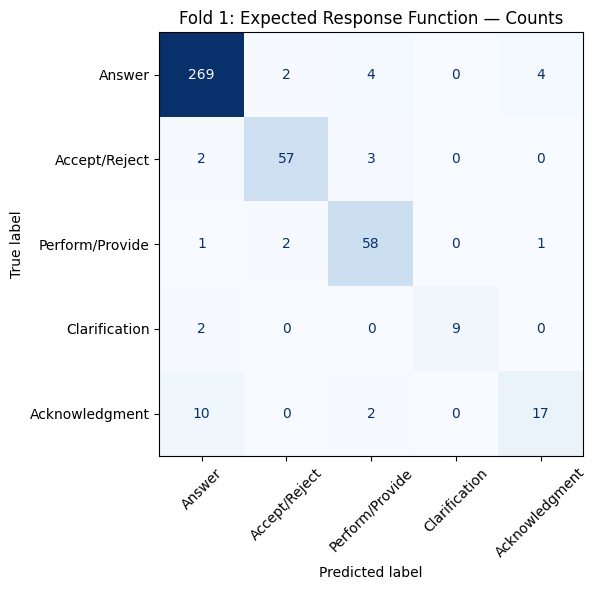

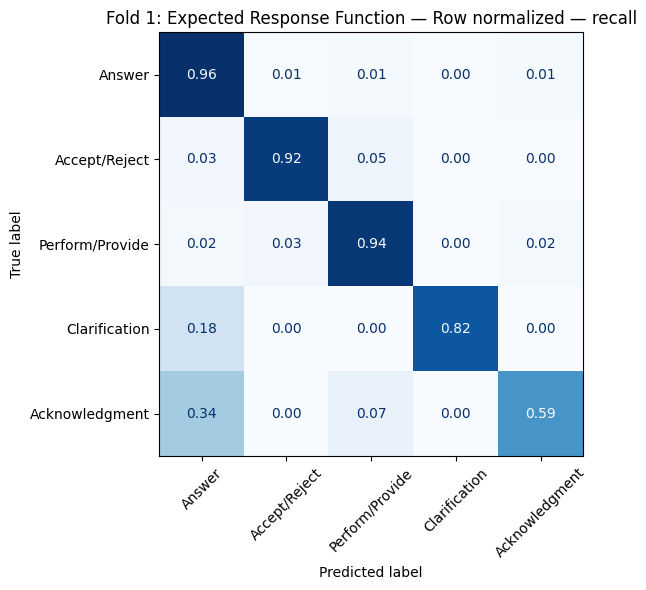

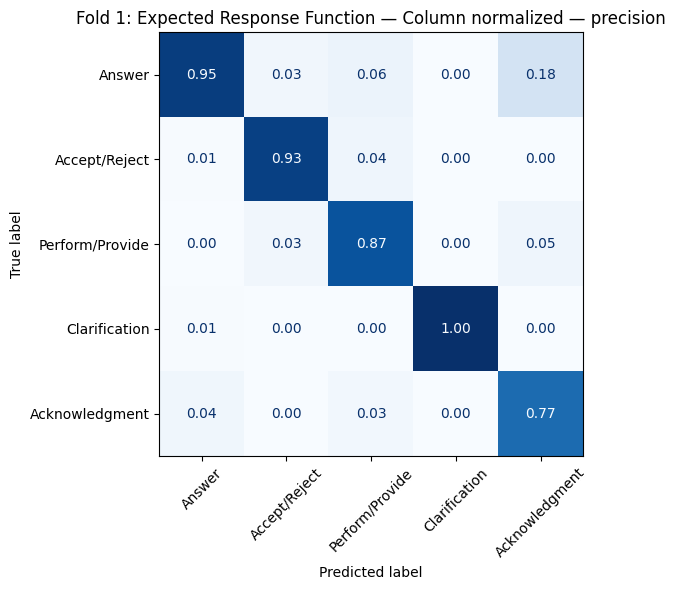


=== Fold 1: Actual Function ===
accuracy              0.9074
macro_precision       0.7331
macro_recall          0.7334
macro_f1              0.7324
weighted_precision    0.8997
weighted_recall       0.9074
weighted_f1           0.9029


,precision,recall,f1-score,support
Answer,0.9496,0.9658,0.9576,234.0000
Accept/Reject,0.9000,0.7895,0.8411,57.0000
Perform/Provide,0.8889,0.8889,0.8889,18.0000
Clarification,0.0000,0.0000,0.0000,6.0000
Acknowledgment,0.7879,0.8387,0.8125,31.0000
Information Request,0.8725,0.9175,0.8945,97.0000
accuracy,0.9074,0.9074,0.9074,0.9074
macro avg,0.7331,0.7334,0.7324,443.0000
weighted avg,0.8997,0.9074,0.9029,443.0000


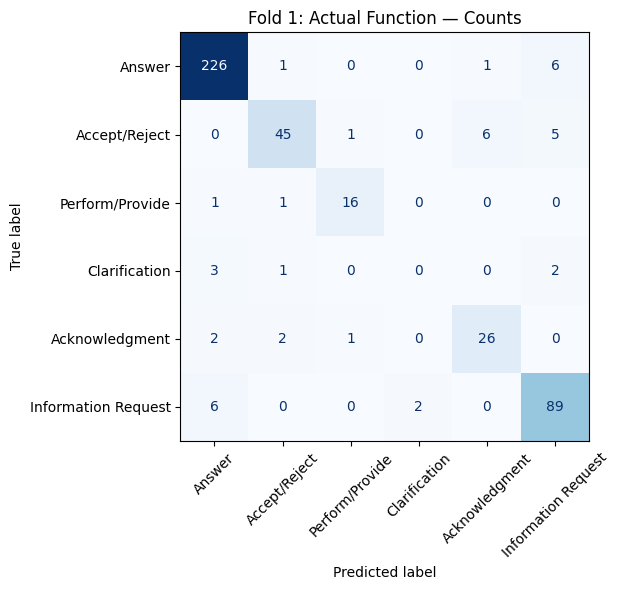

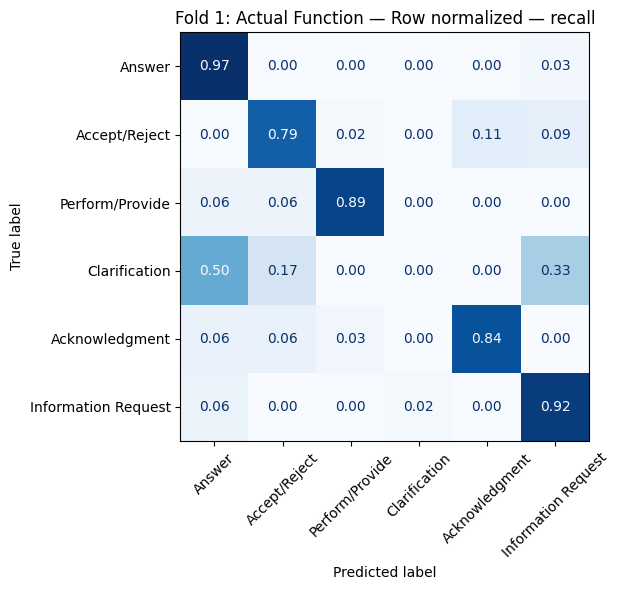

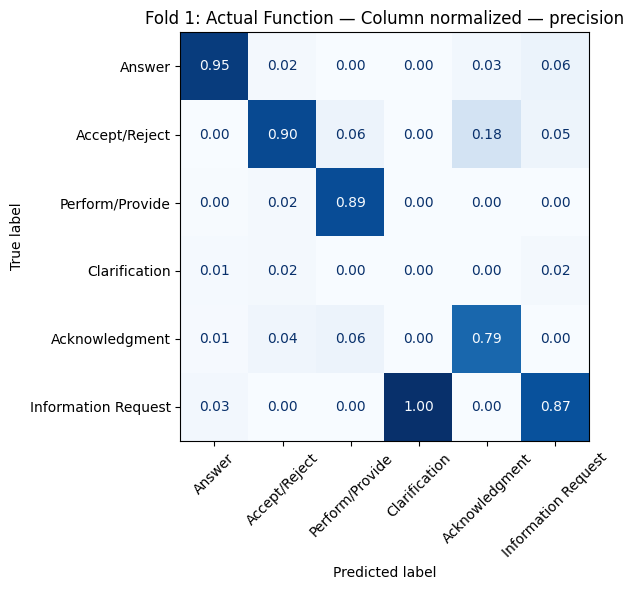


=== Fold 1: Fulfillment ===
accuracy              0.8420
macro_precision       0.8447
macro_recall          0.8423
macro_f1              0.8418
weighted_precision    0.8449
weighted_recall       0.8420
weighted_f1           0.8417


,precision,recall,f1-score,support
Fulfilled,0.8125,0.8864,0.8478,220.000
Not Fulfilled,0.8768,0.7982,0.8357,223.000
accuracy,0.8420,0.8420,0.8420,0.842
macro avg,0.8447,0.8423,0.8418,443.000
weighted avg,0.8449,0.8420,0.8417,443.000


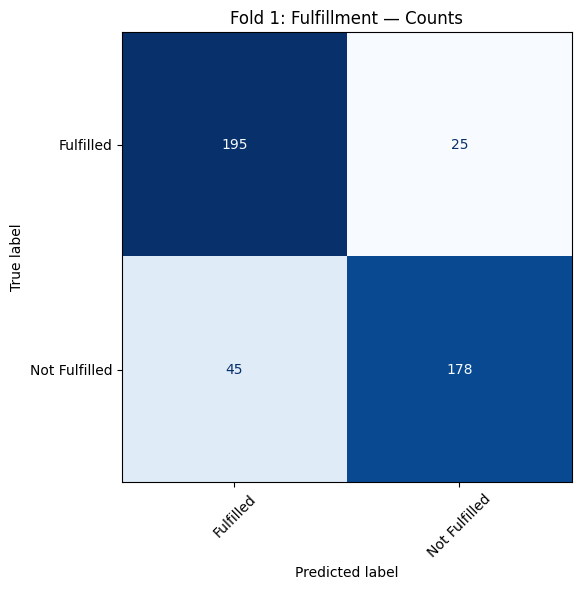

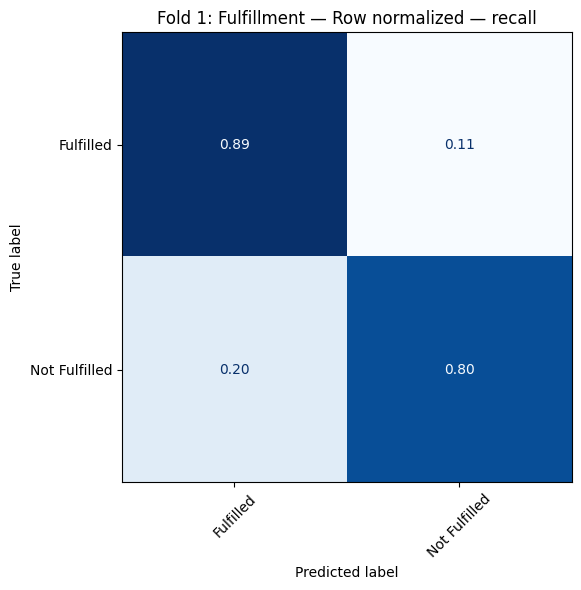

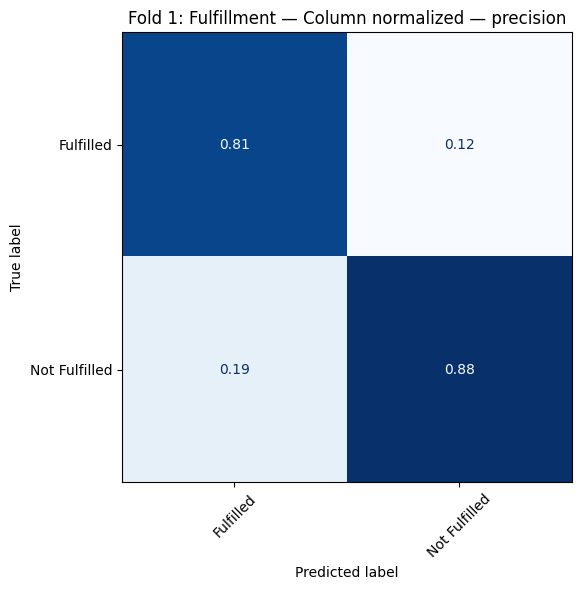

Predictions saved: /content/drive/MyDrive/NLP_Mistral_Final_3Tasks/a16a24b7e22a_groupcv_v1/fold_1/predictions_fold_1.csv
Metrics saved: /content/drive/MyDrive/NLP_Mistral_Final_3Tasks/a16a24b7e22a_groupcv_v1/fold_1/metrics_fold_1.csv


,fold,task,test_pairs,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,invalid_predictions
0,1,Expected Response Function,443,0.9255,0.9040,0.8447,0.8697,0.9239,0.9255,0.9234,0
1,1,Actual Function,443,0.9074,0.7331,0.7334,0.7324,0.8997,0.9074,0.9029,0
2,1,Fulfillment,443,0.8420,0.8447,0.8423,0.8418,0.8449,0.8420,0.8417,0


In [ ]:
results = test_df[['pair_id','dialogue_id','context','previous_utterance','response']].copy()
results['fold'] = FOLD
metrics, class_rows = [], []
KEYS = {'Expected Response Function':'expected','Actual Function':'actual','Fulfillment':'fulfillment'}
SCORE_COLUMNS = ['accuracy','macro_precision','macro_recall','macro_f1',
                 'weighted_precision','weighted_recall','weighted_f1']

def report_task(y_true, y_pred, task, title, out_dir, prefix):
    labels = EVAL_LABELS[task]
    # Include every predicted label, including __INVALID__, in the matrix.
    matrix_labels = labels + [x for x in CLASS_LABELS[task] + ['__INVALID__']
                              if x not in labels and x in y_pred]
    assert set(y_true).issubset(matrix_labels) and set(y_pred).issubset(matrix_labels)
    report = classification_report(y_true, y_pred, labels=labels, zero_division=0, output_dict=True)
    report_df = pd.DataFrame(report).T
    scores = {'accuracy':accuracy_score(y_true,y_pred),
              'macro_precision':precision_score(y_true,y_pred,labels=labels,average='macro',zero_division=0),
              'macro_recall':recall_score(y_true,y_pred,labels=labels,average='macro',zero_division=0),
              'macro_f1':f1_score(y_true,y_pred,labels=labels,average='macro',zero_division=0),
              'weighted_precision':precision_score(y_true,y_pred,labels=labels,average='weighted',zero_division=0),
              'weighted_recall':recall_score(y_true,y_pred,labels=labels,average='weighted',zero_division=0),
              'weighted_f1':f1_score(y_true,y_pred,labels=labels,average='weighted',zero_division=0)}
    print('\n===',title,'===')
    print(pd.Series(scores).round(4).to_string())
    display(report_df.round(4))
    report_df.to_csv(f'{out_dir}/{prefix}_classification_report.csv',index_label='class_or_average')
    for norm, suffix, caption in [(None,'counts','Counts'),
                                 ('true','recall','Row normalized — recall'),
                                 ('pred','precision','Column normalized — precision')]:
        cm = confusion_matrix(y_true,y_pred,labels=matrix_labels,normalize=norm)
        if norm is None:
            assert cm.sum() == len(y_true), 'Confusion matrix omitted test samples'
        pd.DataFrame(cm,index=matrix_labels,columns=matrix_labels).to_csv(
            f'{out_dir}/{prefix}_confusion_{suffix}.csv',index_label='true_label / predicted_label')
        fig, ax = plt.subplots(figsize=(8,6))
        ConfusionMatrixDisplay(cm,display_labels=matrix_labels).plot(
            ax=ax, cmap='Blues', values_format='d' if norm is None else '.2f',
            xticks_rotation=45, colorbar=False)
        ax.set_title(f'{title} — {caption}')
        fig.tight_layout()
        fig.savefig(f'{out_dir}/{prefix}_confusion_{suffix}.png',dpi=160,bbox_inches='tight')
        plt.show()
        plt.close(fig)
    return scores, report

for task in TASK_ORDER:
    key = KEYS[task]
    y_true = test_df[task].tolist()
    y_pred = all_predictions[task]
    results[f'true_{key}'] = y_true
    results[f'pred_{key}'] = y_pred
    results[f'raw_{key}'] = all_raw_generations[task]
    scores, report = report_task(y_true, y_pred, task, f'Fold {FOLD}: {task}', OUTPUT_DIR, key)
    metrics.append({'fold':FOLD,'task':task,'test_pairs':len(y_true),
                    'dataset_sha256':DATA_HASH,'split_sha256':SPLIT_HASH, **scores,
                    'invalid_predictions':sum(p=='__INVALID__' for p in y_pred)})
    for lab in EVAL_LABELS[task]:
        class_rows.append({'fold':FOLD,'task':task,'class':lab,**report[lab]})

pred_path = f'{OUTPUT_DIR}/predictions_fold_{FOLD}.csv'
metric_path = f'{OUTPUT_DIR}/metrics_fold_{FOLD}.csv'
results.to_csv(pred_path,index=False)
pd.DataFrame(metrics).to_csv(metric_path,index=False)
pd.DataFrame(class_rows).to_csv(f'{OUTPUT_DIR}/per_class_metrics_fold_{FOLD}.csv',index=False)
print('Predictions saved:',pred_path)
print('Metrics saved:',metric_path)
display(pd.DataFrame(metrics).drop(columns=['dataset_sha256','split_sha256']).round(4))

## 11. Cross-validation summary (mean ± sample standard deviation)

Run after each fold. Standard deviation across folds requires at least two independent fold scores; the summary explicitly displays `Pending (1 fold)` instead of a misleading zero or unexplained NA. The complete five-fold result uses all five scores. Once all folds are finished, pooled out-of-fold confusion matrices and per-class reports are also generated.

In [ ]:
metric_files = sorted(Path(OUTPUT_ROOT).glob('fold_*/metrics_fold_*.csv'))
if not metric_files:
    print('No completed folds yet.')
else:
    m = pd.concat([pd.read_csv(p) for p in metric_files],ignore_index=True)
    assert m['dataset_sha256'].eq(DATA_HASH).all(), 'Mixed datasets'
    assert m['split_sha256'].eq(SPLIT_HASH).all(), 'Mixed splits'
    assert not m.duplicated(['fold','task']).any(), 'Duplicate fold/task metrics'
    assert set(m['fold']).issubset(set(range(1,6)))
    for k, sub in m.groupby('fold'):
        assert set(sub['task']) == set(TASK_ORDER), f'Incomplete fold {k}'
    completed = sorted(m['fold'].unique())
    print(f'Completed folds: {len(completed)}/5 — {completed}')
    display(m.drop(columns=['dataset_sha256','split_sha256']).sort_values(['task','fold']).round(4))
    rows = []
    for task, sub in m.groupby('task',sort=False):
        for metric in SCORE_COLUMNS:
            values = sub[metric]
            count = len(values)
            mean = values.mean()
            sd = values.std(ddof=1) if count >= 2 else None
            rows.append({'task':task,'metric':metric,'completed_folds':count,
                         'mean':mean,'std':sd,
                         'mean ± std':f'{mean:.4f} ± {sd:.4f}' if count>=2 else f'{mean:.4f} ± Pending (1 fold)'})
    summary = pd.DataFrame(rows)
    display(summary.pivot(index='task',columns='metric',values='mean ± std').reindex(columns=SCORE_COLUMNS))
    m.to_csv(f'{OUTPUT_ROOT}/all_fold_metrics.csv',index=False)
    summary.to_csv(f'{OUTPUT_ROOT}/five_fold_summary.csv',index=False,na_rep='Pending (1 fold)')
    if len(completed) == 5:
        print('All five folds completed: generating pooled out-of-fold evaluation.')
        preds = pd.concat([pd.read_csv(f'{OUTPUT_ROOT}/fold_{k}/predictions_fold_{k}.csv',
                                      dtype=str,keep_default_na=False) for k in completed],ignore_index=True)
        assert preds['pair_id'].is_unique and set(preds['pair_id']) == set(df['pair_id'])
        expected_fold = dict(zip(df['pair_id'],fold_assignment))
        assert preds['pair_id'].map(expected_fold).eq(preds['fold'].astype(int)).all()
        preds.to_csv(f'{OUTPUT_ROOT}/all_out_of_fold_predictions.csv',index=False)
        pooled = []
        for task in TASK_ORDER:
            key = KEYS[task]
            assert preds['pair_id'].map(df.set_index('pair_id')[task]).eq(preds[f'true_{key}']).all()
            scores, _ = report_task(preds[f'true_{key}'].tolist(),preds[f'pred_{key}'].tolist(),
                                    task,f'All 5 folds (pooled): {task}',OUTPUT_ROOT,f'pooled_{key}')
            pooled.append({'task':task,'test_pairs':len(preds),**scores})
        pd.DataFrame(pooled).to_csv(f'{OUTPUT_ROOT}/pooled_metrics.csv',index=False)
        display(pd.DataFrame(pooled).round(4))
    else:
        print('Run the remaining folds with a fresh model each time for the final five-fold summary.')

Completed folds: 1/5 — [np.int64(1)]


,fold,task,test_pairs,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,invalid_predictions
1,1,Actual Function,443,0.9074,0.7331,0.7334,0.7324,0.8997,0.9074,0.9029,0
0,1,Expected Response Function,443,0.9255,0.9040,0.8447,0.8697,0.9239,0.9255,0.9234,0
2,1,Fulfillment,443,0.8420,0.8447,0.8423,0.8418,0.8449,0.8420,0.8417,0


metric,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
task,,,,,,,
Actual Function,0.9074 ± Pending (1 fold),0.7331 ± Pending (1 fold),0.7334 ± Pending (1 fold),0.7324 ± Pending (1 fold),0.8997 ± Pending (1 fold),0.9074 ± Pending (1 fold),0.9029 ± Pending (1 fold)
Expected Response Function,0.9255 ± Pending (1 fold),0.9040 ± Pending (1 fold),0.8447 ± Pending (1 fold),0.8697 ± Pending (1 fold),0.9239 ± Pending (1 fold),0.9255 ± Pending (1 fold),0.9234 ± Pending (1 fold)
Fulfillment,0.8420 ± Pending (1 fold),0.8447 ± Pending (1 fold),0.8423 ± Pending (1 fold),0.8418 ± Pending (1 fold),0.8449 ± Pending (1 fold),0.8420 ± Pending (1 fold),0.8417 ± Pending (1 fold)


Run the remaining folds with a fresh model each time for the final five-fold summary.


## Notes for the project report

- Five model fits, one per fold; each fit learns all three tasks with separate task-specific prompts.
- The final source dataset is used as received; fold assignments exist only in memory and result files are separate.
- The original taxonomy definitions are retained. `Unjudgeable` is allowed but has no reference examples in the supplied dataset; macro averages use observed classes only. `None` belongs to Mismatch Type, not Fulfillment.
- Ground-truth labels, dialogue IDs, fold IDs and annotation agreement metadata are not prompt inputs.
- Metrics measure agreement with annotation labels, not human-validated correctness.
- Sample standard deviation (ddof=1) is reported across fold scores; the pooled metrics are a separate evaluation of out-of-fold predictions, not a substitute for fold averages.
- GPU training and generation require running the notebook on Colab.